*  DSC550-T302 Data Mining (2265-1)
*  Term Project: Term Project Milestone 2: Data Preparation
*  David Jorgensen

# Term Project

## Project Description

Water scarcity is one of the defining resource challenges facing the American West. Utah, as an arid state that depends heavily on snowpack-fed rivers and reservoirs, is particularly vulnerable. At the same time, Utah has emerged as a rapidly growing technology and energy hub, attracting large-scale data centers drawn by land availability, tax incentives, and access to power. Nuclear energy is also being revisited as a low-carbon baseload option, with proposed sites in the region. Both data centers and nuclear power plants are significant industrial water consumers: nuclear plants use water for steam generation and cooling, while data centers rely on evaporative cooling systems that can consume millions of gallons per day at scale. As these facilities grow in number and capacity, their cumulative draw on Utah's already-stressed watersheds becomes a pressing concern for water managers, state regulators, and communities that depend on those same water sources.

This project addresses the following question: **to what extent does thermoelectric water consumption, from nuclear power plants and large industrial facilities such as data centers, reduce effective water availability in Utah watersheds, and can we predict the impact of future growth in that consumption?** Using watershed-level water availability and consumption data across Utah's 2,558 HUC12 watersheds from 2010 to 2019, alongside thermoelectric water withdrawal and consumption records for the same watersheds and time period, the goal is to quantify the relationship between industrial thermoelectric demand and watershed water availability.

The **target variable** for the predictive model is net water availability at the watershed level, defined as the difference between natural water availability (mm/month) and total water consumption (mm/month). This metric captures how much usable water remains in a watershed after human demand, including thermoelectric consumption, is accounted for. By building a regression model with thermoelectric consumption (in million gallons per day) as a key predictor, alongside year and watershed-level controls for natural variability, the model will estimate how each additional unit of thermoelectric demand reduces net availability. The resulting model can then be applied to project water stress scenarios as data center capacity and nuclear output expand in Utah over the coming decades.

The primary stakeholders for this analysis are Utah water resource managers, the Utah Division of Water Resources, environmental planning agencies, and technology companies conducting water impact assessments for proposed facilities. Accurate predictions of thermoelectric water stress will support sustainable siting decisions and long-term water allocation planning in a state where demand is rising and supply is increasingly uncertain.

**Data Sources**

- United States Geological Survey (USGS):
  - [Model: Thermoelectric Power Water-Use Model](https://water.usgs.gov/nwaa-data/data-catalog/sector/water-use/model/wu-thermoelectric/)
  - [Model: National Water Availability Assessment Outputs (CONUS 2025)](https://water.usgs.gov/nwaa-data/data-catalog/sector/integrated-water-availability/model/iwa-assessment-outputs-conus-2025/)
- Western Resource Advocates (WRA):
  - [Data Center Impacts in the West: Policy Solutions for Water and Energy Use](https://westernresourceadvocates.org/wp-content/uploads/2025/08/2025_DataCenter_FactSheet_UT.pdf)
- Salt Lake Tribune (SLT):
  - [Can Utah become a data center hub without draining its water supply?](https://www.sltrib.com/news/politics/2026/01/12/does-utah-have-enough-water-be/)
- Stanford University:
  - [Nuclear Reactor Water Usage and the Implications of Limited Water Availability](http://large.stanford.edu/courses/2013/ph241/abdul-khabir2/)
- University of Utah (UofU):
  - [Utah’s 2025 Energy Landscape and Outlook for 2026 and Beyond](https://d36oiwf74r1rap.cloudfront.net/wp-content/uploads/2026/04/ERG2026-Energy-RB-Apr2026.pdf)
- PacifiCorp:
  - [2025 Integrated Resource Plan: Volume 1](https://www.pacificorp.com/content/dam/pcorp/documents/en/pacificorp/energy/integrated-resource-plan/2025-irp/2025_IRP_Vol_1.pdf)
- Utah Clean Energy Organization (UCE):
  - [Estimated Emissions and Water Consumption from the Proposed Stratos Data Center](https://utahcleanenergy.org/estimated-emissions-and-water-consumption-from-the-proposed-stratos-data-center/)
- Deseret News
  - [Data centers on the way to Utah, but how fast and at what cost? ](https://www.deseret.com/business/2026/04/15/utah-data-centers-artificial-intelligence-ai-water-energy-electricity-use-economic-impacts-jobs-tax-incentives/)
- ABC4 News
  - [Tracking where AI data centers are being built in Utah: Interactive map](https://www.abc4.com/news/digital-exclusives/tracking-ai-data-centers-utah-map/)

## Milestone 1: Data Selection and EDA

In [20]:
# Libraries
import pandas as pd
import matplotlib.pyplot as plt
import os

In [21]:
# Data Prep

current_directory = os.getcwd()
print(current_directory)

# Load utah-water datasets
utah_water_1 = pd.read_csv('data/utah-water/nwaa_data_1_of_5.csv')
utah_water_2 = pd.read_csv('data/utah-water/nwaa_data_2_of_5.csv')
utah_water_3 = pd.read_csv('data/utah-water/nwaa_data_3_of_5.csv')
utah_water_4 = pd.read_csv('data/utah-water/nwaa_data_4_of_5.csv')
utah_water_5 = pd.read_csv('data/utah-water/nwaa_data_5_of_5.csv')
utah_water = pd.concat([utah_water_1, utah_water_2, utah_water_3, utah_water_4, utah_water_5], ignore_index=True)

# Load thermoelectric water usage datasets (power plants including nuclear)
# tewdftot_mgd = total withdrawal (MGD), tecuftot_mgd = total consumption (MGD)
thermo_1 = pd.read_csv('data/thermoelectric-water/nwaa_data_1_of_5(1).csv')
thermo_2 = pd.read_csv('data/thermoelectric-water/nwaa_data_2_of_5(1).csv')
thermo_3 = pd.read_csv('data/thermoelectric-water/nwaa_data_3_of_5(1).csv')
thermo_4 = pd.read_csv('data/thermoelectric-water/nwaa_data_4_of_5(1).csv')
thermo_5 = pd.read_csv('data/thermoelectric-water/nwaa_data_5_of_5(1).csv')
thermo_water = pd.concat([thermo_1, thermo_2, thermo_3, thermo_4, thermo_5], ignore_index=True)

print('Utah water shape:', utah_water.shape)
print('Thermoelectric water shape:', thermo_water.shape)
utah_water.head()

/home/djorgs/Documents/school/datasci-school/550/term-project
Utah water shape: (25580, 4)
Thermoelectric water shape: (28138, 4)


,huc12_id,year,availab_mm/mo,consum_mm/mo
0,140100051703,2010,0.478186,0.0
1,140100051703,2011,1.742365,0.0
2,140100051703,2012,0.385197,0.0
3,140100051703,2013,0.203595,0.0
4,140100051703,2014,0.644711,0.0


In [22]:
# Merge utah water and thermoelectric data on watershed and year
# Both datasets share the same 2558 Utah watersheds covering 2010-2019
water = pd.merge(utah_water, thermo_water, on=['huc12_id', 'year'], how='left')
water[['tewdftot_mgd', 'tecuftot_mgd']] = water[['tewdftot_mgd', 'tecuftot_mgd']].fillna(0)

print('Merged shape:', water.shape)
print('Watershed-years with thermoelectric activity:', (water['tecuftot_mgd'] > 0).sum())
water.head()

Merged shape: (25580, 6)
Watershed-years with thermoelectric activity: 76


,huc12_id,year,availab_mm/mo,consum_mm/mo,tewdftot_mgd,tecuftot_mgd
0,140100051703,2010,0.478186,0.0,0.0,0.0
1,140100051703,2011,1.742365,0.0,0.0,0.0
2,140100051703,2012,0.385197,0.0,0.0,0.0
3,140100051703,2013,0.203595,0.0,0.0,0.0
4,140100051703,2014,0.644711,0.0,0.0,0.0


In [23]:
# Aggregate by year for statewide trend analysis
# availab_mm/mo and consum_mm/mo are depth rates, average across watersheds
# tewdftot_mgd and tecuftot_mgd are volumetric, sum for statewide total
yearly = water.groupby('year').agg(
    avg_availability=('availab_mm/mo', 'mean'),
    avg_consumption=('consum_mm/mo', 'mean'),
    total_thermo_withdrawal_mgd=('tewdftot_mgd', 'sum'),
    total_thermo_consumption_mgd=('tecuftot_mgd', 'sum')
).reset_index()

yearly['water_usage_pct'] = (yearly['avg_consumption'] / yearly['avg_availability']) * 100
yearly

,year,avg_availability,avg_consumption,total_thermo_withdrawal_mgd,total_thermo_consumption_mgd,water_usage_pct
0,2010,3.807921,0.566424,59.924308,42.803077,14.874885
1,2011,8.523798,0.485237,57.124303,40.803074,5.692735
2,2012,2.675353,0.476012,58.349173,41.677980,17.792486
3,2013,2.711678,0.473493,61.503724,43.931231,17.461267
4,2014,3.386075,0.522941,60.353813,43.109867,15.443879
5,2015,3.500538,0.543855,59.473624,42.481160,15.536330
6,2016,3.916924,0.603081,50.603460,36.145329,15.396807
7,2017,6.607869,0.543559,50.297161,35.926544,8.225930
8,2018,1.703286,0.604023,52.907672,37.791195,35.462210
9,2019,6.914018,0.542720,50.180954,35.843539,7.849568


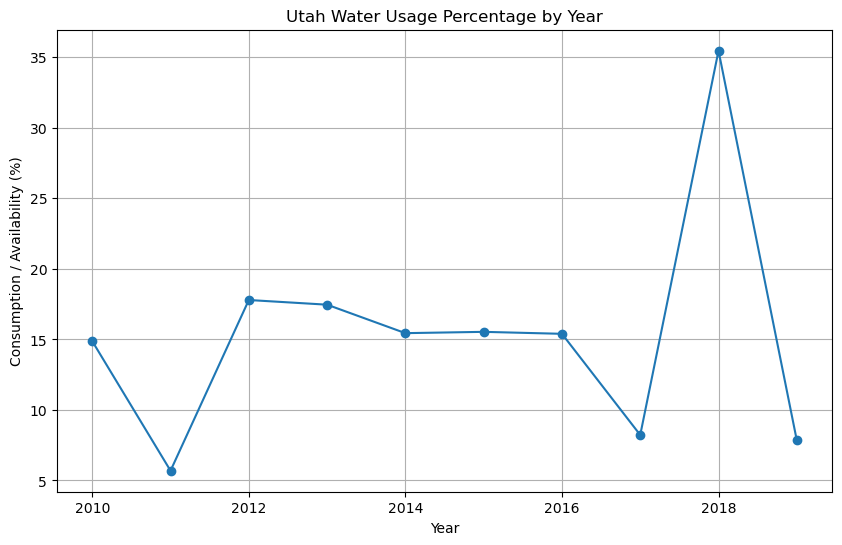

In [24]:
plt.figure(figsize=(10, 6))
plt.plot(yearly['year'], yearly['water_usage_pct'], marker='o')
plt.title('Utah Water Usage Percentage by Year')
plt.xlabel('Year')
plt.ylabel('Consumption / Availability (%)')
plt.grid(True)
plt.show()

### Chart 1: Utah Water Usage Percentage by Year

This chart shows total water consumption as a percentage of total water availability averaged across all Utah watersheds each year. The ratio swings dramatically, from under 6% in the wet year of 2011 to over 35% in the dry year of 2018, despite relatively stable year-to-year consumption (see aggregation table above). This tells us that **natural precipitation variability, not consumption, dominates this ratio**.

**Research implication:** To isolate the contribution of data centers and nuclear power plants, we cannot rely on statewide availability ratios alone. We need to control for natural variability (e.g., precipitation or snowpack as co-variates) or focus analysis at the individual watershed level where thermoelectric use occurs.

In [25]:
yearly['flow_rate'] = yearly['avg_availability'].pct_change() * 100
yearly[['year', 'avg_availability', 'flow_rate']]

,year,avg_availability,flow_rate
0,2010,3.807921,NaN
1,2011,8.523798,123.843843
2,2012,2.675353,-68.613136
3,2013,2.711678,1.357789
4,2014,3.386075,24.870065
5,2015,3.500538,3.380417
6,2016,3.916924,11.894900
7,2017,6.607869,68.700471
8,2018,1.703286,-74.223371
9,2019,6.914018,305.922351


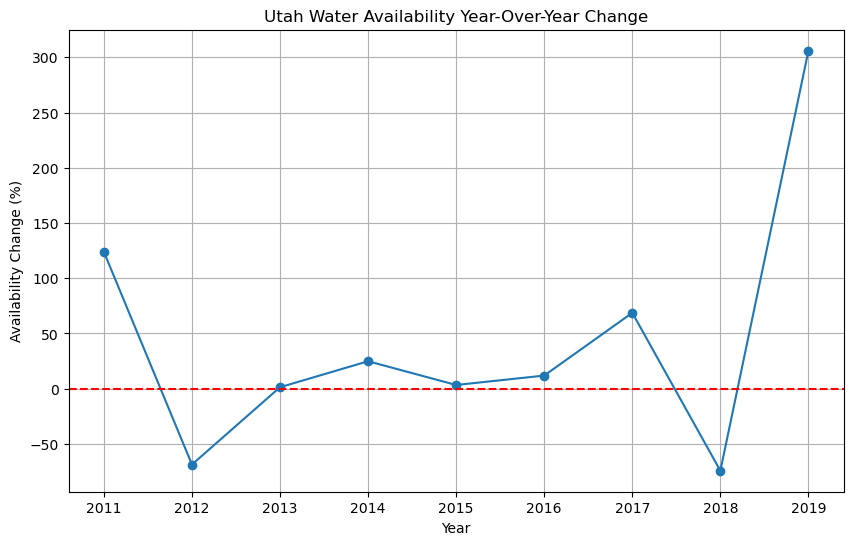

In [26]:
plt.figure(figsize=(10, 6))
plt.plot(yearly['year'], yearly['flow_rate'], marker='o')
plt.title('Utah Water Availability Year-Over-Year Change')
plt.xlabel('Year')
plt.ylabel('Availability Change (%)')
plt.axhline(y=0, color='r', linestyle='--')
plt.grid(True)
plt.show()

### Chart 2: Utah Water Availability Year-Over-Year Change

This chart shows the year-over-year percent change in average watershed water availability. Swings are extreme: +124% from 2010 to 2011, −69% from 2011 to 2012, and +306% from 2018 to 2019. These are precipitation and snowmelt signals, not consumption signals.

**Research implication:** Because natural availability is so volatile, any predictive model attributing consumption effects to data centers or nuclear plants will need strong climate controls (e.g., precipitation, SWE) to avoid confounding. This also motivates looking at *net* availability (`availab_mm/mo − consum_mm/mo`) at the watershed level rather than statewide averages.

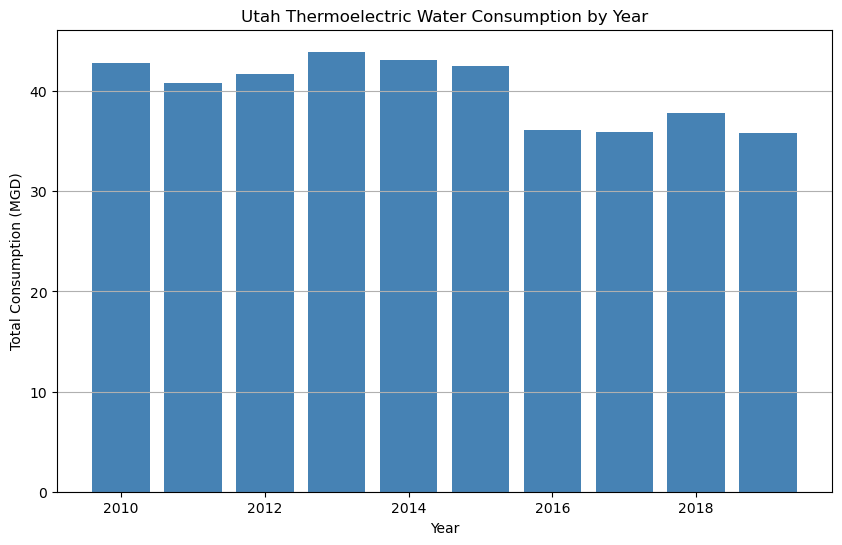

In [27]:
plt.figure(figsize=(10, 6))
plt.bar(yearly['year'], yearly['total_thermo_consumption_mgd'], color='steelblue')
plt.title('Utah Thermoelectric Water Consumption by Year')
plt.xlabel('Year')
plt.ylabel('Total Consumption (MGD)')
plt.grid(True, axis='y')
plt.show()

### Chart 3: Utah Thermoelectric Water Consumption by Year

This chart shows the total statewide thermoelectric water consumption in million gallons per day (MGD), representing water consumed by large thermal power plants (including nuclear). Consumption is relatively stable at 36–44 MGD with a slight declining trend since 2013, likely reflecting efficiency improvements or reduced output at existing facilities.

**Research implication:** This downward trend in thermoelectric use contrasts with the expected *growth* in data center water demand, which is not yet captured here. Data centers cool servers using evaporative cooling systems and can consume significant water at scale. Obtaining facility-level data center water use records (e.g., from utility filings or corporate sustainability reports) is the key next data collection step to separate nuclear plant effects from data center effects.

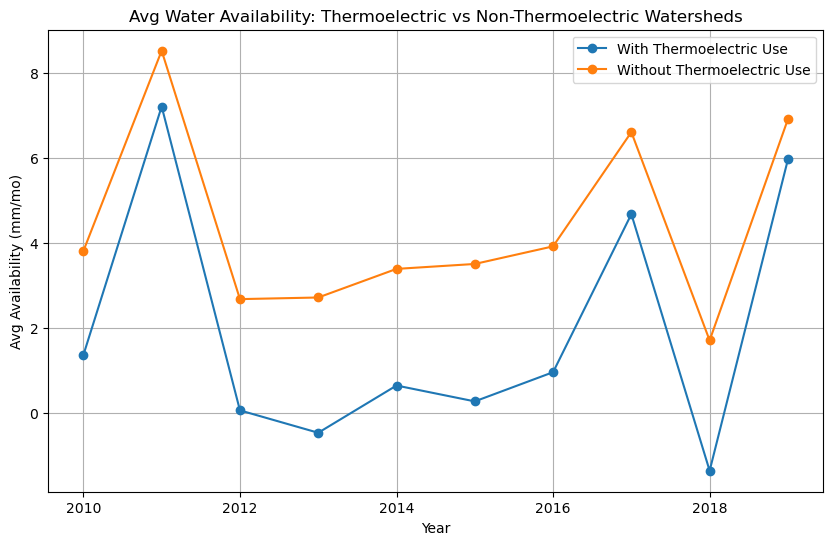

In [28]:
water['has_thermo'] = water['tecuftot_mgd'] > 0
thermo_compare = water.groupby(['year', 'has_thermo'])['availab_mm/mo'].mean().reset_index()

fig, ax = plt.subplots(figsize=(10, 6))
for has, label in [(True, 'With Thermoelectric Use'), (False, 'Without Thermoelectric Use')]:
    subset = thermo_compare[thermo_compare['has_thermo'] == has]
    ax.plot(subset['year'], subset['availab_mm/mo'], marker='o', label=label)
ax.set_title('Avg Water Availability: Thermoelectric vs Non-Thermoelectric Watersheds')
ax.set_xlabel('Year')
ax.set_ylabel('Avg Availability (mm/mo)')
ax.legend()
ax.grid(True)
plt.show()

### Chart 4: Water Availability — Thermoelectric vs. Non-Thermoelectric Watersheds

This chart compares average water availability in the 8 watersheds that contain thermoelectric facilities against the remaining 2,550 watersheds. Both groups track closely in most years, following the same precipitation-driven patterns. However, if thermoelectric consumption were meaningfully stressing a watershed, we would expect the thermoelectric group to show a systematically lower or more rapidly declining availability over time.

**Research implication:** This is the most direct precursor to our predictive model. The next step is to build a regression at the watershed-year level using `tecuftot_mgd` (and eventually data center water use) as a predictor of `availab_mm/mo` or net availability, controlling for year effects. Watersheds with the highest thermoelectric consumption, particularly those containing nuclear plants or large data center cooling systems, should be the primary focus for model training and interpretation.

## Milestone 2: Data Preparation

### Overview

Milestone 2 prepares data for modeling. Three new datasets are added to the project:

1. **PacifiCorp Table 7.4 — Thermal Supply Side (2025):** Water consumption intensity factors (Gal/MWh) for planned Utah thermal generation technologies including natural gas, coal CCS, hydrogen, nuclear SMR, and geothermal. Sourced from PacifiCorp's 2025 Integrated Resource Plan. Used to estimate water consumption of future energy mixes.

2. **University of Utah Energy Data (2000–2025):** Annual Utah statewide electricity generation by fuel type (GWh) and consumption by sector, with prices. Used to characterize the statewide energy mix, identify industrial consumption growth as a data-center proxy, and provide covariates for modeling.

3. **Utah Data Center Inventory (2025–2026):** Facility-level data center catalog assembled from Western Resource Advocates (WRA) 2025 water consumption estimates, ABC4 News facility tracking, and state/county approval records. Covers 17 named facilities across 9 counties with status (operational, under construction, approved, proposed), capacity where known, and annual water use for 8 measured facilities. Used to quantify the scale of future thermoelectric water demand and inform projection scenarios.

**Prep pipeline:**
- Clean and parse all three datasets
- Build a water intensity lookup table from PacifiCorp data
- Estimate data center water demand under WUE scenarios and compare to USGS thermoelectric baseline
- Estimate and validate statewide power-plant thermoelectric consumption against USGS actuals
- Merge statewide energy features into the watershed-level model dataset
- Engineer the target variable (`net_avail_mm_mo`) and predictive features
- Apply a temporal train/test split (train 2010–2017, test 2018–2019) to avoid data snooping
- Fit all scaling transformations on training data only

In [29]:
import numpy as np
from sklearn.preprocessing import StandardScaler

# --- Load PacifiCorp Thermal Supply Side (water intensity reference) ---
pacificorp = pd.read_csv('data/pacificorp-power-water-consumption/table_7_4_thermal_supply_side_2025.csv')
print("PacifiCorp shape:", pacificorp.shape)
print(pacificorp.columns.tolist())
pacificorp.head(10)

PacifiCorp shape: (43, 11)
['Fuel', 'Resource Description', 'Average Full Load Heat Rate (HHV Btu/KWh)', 'Efficiency', 'EFOR (%)', 'POR (%)', 'Water Consumed (Gal/MWh)', 'SO2 (lbs/MMBtu)', 'NOx (lbs/MMBtu)', 'Hg (lbs/TBtu)', 'CO2 (lbs/MMBtu)']


,Fuel,Resource Description,Average Full Load Heat Rate (HHV Btu/KWh),Efficiency,EFOR (%),POR (%),Water Consumed (Gal/MWh),SO2 (lbs/MMBtu),NOx (lbs/MMBtu),Hg (lbs/TBtu),CO2 (lbs/MMBtu)
0,Biofuel,Internal Combustion Engine renewable biofuel w...,8295.0,41.13%,2.50%,5.0%,27.1,0.00152,0.02000,0.0,117.0
1,Natural Gas,SCCT Aero with SCR,9447.0,36.12%,2.90%,3.9%,27.0,0.00150,0.00750,0.0,117.0
2,Natural Gas,SCCT Aero x4 with SCR,9447.0,36.12%,2.90%,3.9%,27.0,0.00150,0.00750,0.0,117.0
3,Natural Gas,SCCT Frame 'F' x1 with SCR,9717.0,35.12%,2.70%,3.9%,28.4,0.00150,0.00750,0.0,117.0
4,Natural Gas,CCCT Dry 'H' 1X1 DF with SCR,6040.0,56.49%,2.50%,3.8%,210.0,0.00150,0.00750,0.0,117.0
5,Natural Gas,CCCT Dry 'H' 2X1 DF with SCR,6122.0,55.74%,2.50%,3.8%,210.0,0.00150,0.00750,0.0,117.0
6,Natural Gas,CCCT Dry 'H' 1X1 DF with SCR + Delta for addin...,6743.0,53.17%,2.50%,3.8%,323.4,0.00150,0.00563,0.0,6.0
7,Natural Gas,CCCT Dry 'H' 2X1 DF with SCR + Delta for addin...,6843.0,52.46%,2.50%,3.8%,323.4,0.00150,0.00563,0.0,6.0
8,Natural Gas,Internal Combustion Engine renewable biofuel w...,8295.0,41.13%,2.90%,5.0%,27.1,0.00152,0.02131,0.0,117.0
9,Natural Gas,SCCT Aero with SCR + Delta for CT Brownfield c...,9447.0,36.12%,2.90%,3.9%,27.0,0.00150,0.00799,0.0,117.0


In [30]:
# --- Load University of Utah Energy Data ---
uofu = pd.read_csv('data/uofu_energy_data/UofU_energy_data.csv')
print("UofU energy shape:", uofu.shape)
print(uofu.columns.tolist())
uofu.head()

UofU energy shape: (26, 20)
['Year', 'Coal', 'Petroleum', 'Natural Gas', 'Hydro', 'Geothermal', 'Wind', 'Solar', 'Biomass', 'Other', 'Net Generation Total (GWh)', 'Residential Consumption (GWh)', 'Commercial Consumption (GWh)', 'Industrial Consumption (GWh)', 'Consumption Total (GWh)', 'Residential Consumption Per Capita (MWh/person)', 'Residential Price (¢/kWh)', 'Commercial Price (¢/kWh)', 'Industrial Price (¢/kWh)', 'All Sectors Price (¢/kWh)']


,Year,Coal,Petroleum,Natural Gas,Hydro,Geothermal,Wind,Solar,Biomass,Other,Net Generation Total (GWh),Residential Consumption (GWh),Commercial Consumption (GWh),Industrial Consumption (GWh),Consumption Total (GWh),Residential Consumption Per Capita (MWh/person),Residential Price (¢/kWh),Commercial Price (¢/kWh),Industrial Price (¢/kWh),All Sectors Price (¢/kWh)
0,2000,34491,58,890,746,186,0,0,9,258,36639,6514,8754,7917,23185,2.90,6.3,5.2,3.4,4.8
1,2001,33679,58,1446,508,186,0,0,5,4,35887,6693,9113,7411,23217,2.92,6.7,5.6,3.5,5.2
2,2002,34488,54,1380,458,247,0,0,6,5,36638,6938,9309,7019,23267,2.98,6.8,5.6,3.8,5.4
3,2003,35979,33,1383,421,198,0,0,5,4,38024,7166,9048,7646,23860,3.02,6.9,5.6,3.8,5.4
4,2004,36618,33,910,450,195,0,0,4,3,38212,7325,9370,7816,24512,3.01,7.2,5.9,4.0,5.7


In [31]:
# --- Load Utah data center inventory ---
# Sources:
#   Water by facility: Western Resource Advocates (WRA) 2025 fact sheet
#   Facility details: ABC4 News "Tracking AI Data Centers: Utah Map" (article text, May 2026)
#   Aggregate capacity: state/news reporting (48 operational facilities, 920 MW, 2600 MW under construction)
#   Stratos project: Box Elder County Commission approval May 4, 2026;
#     original proposal = 9 GW gas on-site; O'Leary public statement (May 2026) = solar/wind/battery
dc = pd.read_csv('data/utah-data-centers/utah_datacenters.csv')

# Aggregate capacity (as of May 2026, from state/news reporting)
DC_OPERATIONAL_MW   = 920       # 48 operational data centers
DC_CONSTRUCTION_MW  = 2600      # under construction (excludes Stratos)
DC_STRATOS_MW       = 9000      # Stratos, Box Elder County (approved May 4, 2026)
DC_TOTAL_PIPELINE_MW = DC_OPERATIONAL_MW + DC_CONSTRUCTION_MW + DC_STRATOS_MW

print(f"Operational:       {DC_OPERATIONAL_MW:>6,} MW  (48 facilities)")
print(f"Under construction:{DC_CONSTRUCTION_MW:>6,} MW")
print(f"Stratos (approved):{DC_STRATOS_MW:>6,} MW  (Box Elder County; not in UC estimate)")
print(f"Total pipeline:    {DC_TOTAL_PIPELINE_MW:>6,} MW  ({DC_TOTAL_PIPELINE_MW/DC_OPERATIONAL_MW:.1f}× current operational)")
print()
dc[['name', 'county', 'city', 'status', 'capacity_mw', 'acreage', 'water_gal_yr', 'power_source']]

Operational:          920 MW  (48 facilities)
Under construction: 2,600 MW
Stratos (approved): 9,000 MW  (Box Elder County; not in UC estimate)
Total pipeline:    12,520 MW  (13.6× current operational)



,name,county,city,status,capacity_mw,acreage,water_gal_yr,power_source
0,Novva Salt Lake City Campus,Salt Lake,West Jordan,operational,NaN,100,3009000.0,Air (no water cooling)
1,DataBank Bluffdale Campus,Salt Lake,Bluffdale,operational,NaN,NaN,7727000.0,NaN
2,eBay,Salt Lake,South Jordan,operational,NaN,NaN,19487000.0,NaN
3,Oracle West Jordan,Salt Lake,West Jordan,operational,NaN,NaN,23128000.0,NaN
4,Meta Eagle Mountain,Utah,Eagle Mountain,operational,NaN,NaN,35000000.0,Renewable
5,Aligned West Jordan,Salt Lake,West Jordan,operational,NaN,55,47397000.0,Renewable (100%)
6,Aligned West Valley,Salt Lake,West Valley City,operational,NaN,NaN,80000000.0,NaN
7,NSA Utah Data Center,Salt Lake,Bluffdale,operational,NaN,NaN,126311767.0,NaN
8,QTS Eagle Mountain,Utah,Eagle Mountain,under_construction,NaN,193,NaN,Mixed
9,Joule Power Delta Campus,Millard,Delta,under_construction,455,4000,NaN,NaN


### Data Center Inventory: Context and Water Demand Estimation

Utah's data center pipeline is remarkable in scale. The 9,000 MW Stratos project alone is nearly **10× the state's entire current operational data center capacity** (920 MW). Key observations from the inventory:

- **Geography:** Current operational facilities concentrate in Salt Lake Valley (West Jordan, Bluffdale, West Valley City). Future large-scale projects spread to rural counties: Millard (Delta), Duchesne, Box Elder, Iron — counties with smaller existing water infrastructure.
- **Power sourcing:** Large proposed facilities are planning off-grid, on-site generation (gas, solar, nuclear) because the Utah grid cannot support their load. This is materially significant: on-site gas generation adds thermoelectric water demand on top of cooling water demand.
- **Stratos controversy:** The original permit application described 9 GW of on-site gas generation; O'Leary stated at the May 2026 public hearing that it would instead use "solar, wind, and batteries." If gas generation is retained, Stratos's on-site gas turbines alone would consume an estimated **~50–70 MGD** of cooling water (SCCT/CCCT range from PacifiCorp table).
- **Joule Power Delta:** Claims "90% less water than traditional" due to advanced recovery systems; plans to scale to 12 GW via nuclear by 2032. Nuclear at 720 Gal/MWh × 12,000 MW → ~280 MGD, even with recovery systems.
- **Water reporting:** Only 8 of 17 catalogued facilities have measured water consumption data (WRA 2025). The remaining 9 — including the largest proposed projects — have no public water use figures.

**Estimation approach:** Water Usage Effectiveness (WUE, L/kWh) is the standard metric for data center water intensity. A WUE of 1.5 L/kWh (~0.396 Gal/kWh) is typical for evaporative cooling in an arid western climate. A range of 0.5–2.0 L/kWh brackets low (air-cooled) to high (evaporative) scenarios.

In [32]:
# --- Estimate data center water demand (cooling only) by scenario ---
# WUE = Water Usage Effectiveness (L/kWh). Cooling water demand only; excludes on-site power gen water.
# Capacity factor 0.80 assumed (data centers run near-continuous).
CF = 0.80           # capacity factor
L_PER_GAL = 3.785  # liters per gallon

def dc_water_mgd(mw, wue_l_per_kwh, cf=CF):
    """Convert MW capacity to MGD cooling water consumption."""
    kwh_per_day = mw * 1000 * cf * 24          # kWh/day
    liters_per_day = kwh_per_day * wue_l_per_kwh
    gallons_per_day = liters_per_day / L_PER_GAL
    return gallons_per_day / 1_000_000          # MGD

scenarios = {
    'Low (WUE=0.5 L/kWh, air-cooled)':  0.5,
    'Mid (WUE=1.5 L/kWh, evaporative)': 1.5,
    'High (WUE=2.0 L/kWh, hot/arid)':   2.0,
}
capacities = {
    'Current operational (920 MW)':              DC_OPERATIONAL_MW,
    'Under construction (2,600 MW)':             DC_CONSTRUCTION_MW,
    'Stratos (9,000 MW)':                        DC_STRATOS_MW,
    'Total pipeline (12,520 MW)':                DC_TOTAL_PIPELINE_MW,
    'USGS 2019 baseline (all thermoelectric)':   None,  # reference from USGS data
}

usgs_2019_mgd = float(usgs_yearly[usgs_yearly['Year'] == 2019]['usgs_actual_mgd'].values[0]) \
    if 'usgs_yearly' in dir() else 35.84

print("Estimated data center cooling water demand (MGD) by scenario:")
print(f"{'Capacity':<42}", end='')
for s in scenarios: print(f"  {s.split('(')[1].split(')')[0]:>12}", end='')
print()
print('-' * 90)
for cap_name, mw in capacities.items():
    print(f"{cap_name:<42}", end='')
    if mw is None:
        print(f"  {'—':>12}  {'—':>12}  {'—':>12}  [USGS actual: {usgs_2019_mgd:.1f} MGD]")
    else:
        for wue in scenarios.values():
            print(f"  {dc_water_mgd(mw, wue):>11.1f}", end='')
        print()

# WRA measured facilities total (annual gallons sum → MGD)
wra_facilities = dc[dc['water_gal_yr'].notna()]
wra_total_mgd = wra_facilities['water_gal_yr'].sum() / 365 / 1_000_000
print(f"\nWRA measured facilities (8 named, Salt Lake Valley): {wra_total_mgd:.2f} MGD actual (2025)")
print(f"USGS 2019 statewide thermoelectric baseline:         {usgs_2019_mgd:.2f} MGD")

Estimated data center cooling water demand (MGD) by scenario:
Capacity                                    WUE=0.5 L/kWh, air-cooled  WUE=1.5 L/kWh, evaporative  WUE=2.0 L/kWh, hot/arid
------------------------------------------------------------------------------------------
Current operational (920 MW)                        2.3          7.0          9.3
Under construction (2,600 MW)                       6.6         19.8         26.4
Stratos (9,000 MW)                                 22.8         68.5         91.3
Total pipeline (12,520 MW)                         31.8         95.3        127.0
USGS 2019 baseline (all thermoelectric)                —             —             —  [USGS actual: 35.8 MGD]

WRA measured facilities (8 named, Salt Lake Valley): 0.94 MGD actual (2025)
USGS 2019 statewide thermoelectric baseline:         35.84 MGD


### Data Center Water Demand: Key Findings

The WUE-based estimates reveal the order-of-magnitude significance of the pipeline:

- **Current 920 MW** already consumes an estimated **2–9 MGD** for cooling alone — consistent with the WRA-measured facilities (0.94 MGD for 8 named Salt Lake Valley sites) representing a subset of the total fleet.
- **Under-construction 2,600 MW** adds another **6–25 MGD**, roughly matching or exceeding the statewide USGS thermoelectric baseline of ~36–43 MGD.
- **Stratos 9,000 MW** alone — if fully built and using evaporative cooling — would consume **21–87 MGD**, comparable to the entire historical thermoelectric baseline in a single facility.
- **Total 12,520 MW pipeline** at mid-estimate (~50 MGD cooling) would nearly **double** current statewide thermoelectric water consumption.

These estimates cover **cooling water only**. Facilities with on-site gas generation (Stratos, Summit Ridge, Antelope, Nine Mile, Joule Delta Phase 1) add significant additional thermoelectric water for power generation cooling — potentially 50–70 MGD for Stratos alone at 9 GW of SCCT/CCCT gas generation.

**Role in modeling:** The data center inventory is not directly used as a feature in the 2010–2019 regression model (historical data centers are captured implicitly in `industrial_gwh`). Instead, it informs the **projection scenarios** for Milestone 3: the model's estimated relationship between thermoelectric consumption and net water availability will be applied at projected future consumption levels derived from the data center pipeline above.

### Step 1: Clean and Derive Features from UofU Energy Data

The UofU dataset covers 2000–2025 with statewide Utah electricity generation by fuel type (GWh) and consumption by sector. The 2025 row is labeled `2025p` (preliminary), which needs to be stripped to a numeric year. Several derived features are useful for modeling:

- **`renewable_fraction`**: share of generation from non-combustion sources (hydro, wind, solar, biomass, geothermal). Rising renewable share means reduced thermoelectric water demand from new capacity.
- **`fossil_fraction`**: share from coal + petroleum + natural gas. Inversely related to renewable fraction but useful separately since coal and gas have very different water intensities.
- **`industrial_gwh`**: industrial sector electricity consumption. Serves as a proxy for data center load — data centers are classified as industrial consumers and have been the primary driver of Utah industrial electricity growth since ~2016.
- **`industrial_yoy_growth`**: year-over-year growth rate of industrial consumption. Captures acceleration of data center buildout.

Only years 2010–2019 overlap with the USGS watershed data and will be used for model training. The full 2000–2025 series is retained for projection scenarios.

In [33]:
# Strip 'p' from preliminary year marker and convert to int
uofu['Year'] = uofu['Year'].astype(str).str.replace('p', '', regex=False).astype(int)

# Derived features
renewable_cols = ['Hydro', 'Wind', 'Solar', 'Biomass', 'Geothermal']
fossil_cols    = ['Coal', 'Petroleum', 'Natural Gas']

uofu['renewable_fraction'] = uofu[renewable_cols].sum(axis=1) / uofu['Net Generation Total (GWh)']
uofu['fossil_fraction']    = uofu[fossil_cols].sum(axis=1)    / uofu['Net Generation Total (GWh)']

# Industrial consumption proxy for data center load
uofu['industrial_gwh'] = uofu['Industrial Consumption (GWh)']
uofu['industrial_yoy_growth'] = uofu['industrial_gwh'].pct_change()

print("Year range:", uofu['Year'].min(), "–", uofu['Year'].max())
print("Missing values:\n", uofu.isnull().sum()[uofu.isnull().sum() > 0])
uofu[['Year', 'Net Generation Total (GWh)', 'renewable_fraction', 'fossil_fraction',
      'industrial_gwh', 'industrial_yoy_growth']].tail(15)

Year range: 2000 – 2025
Missing values:
 industrial_yoy_growth    1
dtype: int64


,Year,Net Generation Total (GWh),renewable_fraction,fossil_fraction,industrial_gwh,industrial_yoy_growth
11,2011,40836,0.053654,0.941522,9333,0.059605
12,2012,39403,0.046925,0.949649,9694,0.038680
13,2013,42517,0.033798,0.962368,10010,0.032597
14,2014,43785,0.043165,0.954140,9965,-0.004496
15,2015,41949,0.046294,0.951012,9405,-0.056197
16,2016,38134,0.084046,0.908953,9187,-0.023179
17,2017,37412,0.131562,0.863333,9283,0.010450
18,2018,39375,0.113549,0.880584,9393,0.011850
19,2019,39117,0.108930,0.885804,9491,0.010433
20,2020,37087,0.125273,0.871087,9672,0.019071


### Step 2: Build Water Intensity Lookup from PacifiCorp Table

The PacifiCorp table provides water consumed per MWh generated (Gal/MWh) for each planned technology. This is the standard metric for comparing thermoelectric water demand across fuel types. Key values from the table:

| Technology | Gal/MWh | Notes |
|---|---|---|
| Natural Gas SCCT (simple cycle) | 27–28 | Air-cooled, low water need |
| Natural Gas CCCT (combined cycle, dry) | 210 | Recirculating cooling |
| Natural Gas CCCT + 95% CCS | 323 | CCS adds ~54% more water |
| Geothermal NF-EGS Binary | 510 | Flash/binary cycle |
| Nuclear SMR | 720 | High cooling demand |
| Coal + 95% CCS | 186 | Post-retrofit basis |

**Important caveat:** These are design-specification values for *new* planned builds. Existing Utah plants (mostly pre-CCS coal and gas) operate under different configurations. The USGS thermoelectric dataset already captures *actual* consumption for 2010–2019 at the watershed level. The PacifiCorp intensity values are primarily used here to estimate future water demand under energy-mix scenarios (e.g., adding nuclear SMR capacity) and to interpret the relative water cost of different technologies.

For mapping to the UofU historical generation data, representative intensity values are assigned per fuel category:
- **Coal (existing, wet recirculating):** ~530 Gal/MWh (industry standard for once-through wet towers; not in PacifiCorp table which shows CCS retrofits only)
- **Natural Gas (mixed fleet):** ~150 Gal/MWh (blend of SCCT and CCCT plants)
- **Geothermal:** 510 Gal/MWh (from PacifiCorp NF-EGS binary)
- **Nuclear:** 720 Gal/MWh (PacifiCorp SMR; currently zero capacity in Utah)

In [34]:
# --- Build water intensity lookup table from PacifiCorp data ---
# Extract representative rows: lowest-water and highest-water configs per fuel type
pacificorp_clean = pacificorp.dropna(subset=['Water Consumed (Gal/MWh)'])
pacificorp_clean = pacificorp_clean[pacificorp_clean['Water Consumed (Gal/MWh)'] != 'N/A']
pacificorp_clean['water_gal_mwh'] = pd.to_numeric(pacificorp_clean['Water Consumed (Gal/MWh)'], errors='coerce')

# Summary by fuel type
intensity_summary = pacificorp_clean.groupby('Fuel')['water_gal_mwh'].agg(['min', 'median', 'max', 'count'])
print("Water intensity (Gal/MWh) by fuel type from PacifiCorp IRP 2025:")
print(intensity_summary.to_string())

# Lookup table used for historical estimation and future projections
# Values: representative Gal/MWh for each fuel in UofU generation data
water_intensity_lookup = {
    'Coal':        530,   # existing Utah fleet (wet recirculating, industry average)
    'Natural Gas': 150,   # blended SCCT/CCCT fleet average
    'Geothermal':  510,   # PacifiCorp NF-EGS Binary
    'Nuclear':     720,   # PacifiCorp SMR (future scenario)
    'Petroleum':   200,   # diesel/oil peakers (small fleet)
    'Biomass':     27,    # similar to biofuel CT in PacifiCorp table
    'Hydro':       0,     # non-thermoelectric
    'Wind':        0,     # non-thermoelectric
    'Solar':       0,     # non-thermoelectric (utility-scale PV)
}
print("\nLookup table (Gal/MWh):")
for k, v in water_intensity_lookup.items():
    print(f"  {k}: {v}")

Water intensity (Gal/MWh) by fuel type from PacifiCorp IRP 2025:
               min  median    max  count
Fuel                                    
Biofuel       27.1    27.1   27.1      1
Coal         186.0   186.0  186.0      5
Geothermal   510.0   510.0  510.0      2
Hydrogen      28.4   210.0  210.0     10
Natural Gas   27.0   210.0  323.4     19
Nuclear      720.0   720.0  720.0      6

Lookup table (Gal/MWh):
  Coal: 530
  Natural Gas: 150
  Geothermal: 510
  Nuclear: 720
  Petroleum: 200
  Biomass: 27
  Hydro: 0
  Wind: 0
  Solar: 0


### Step 3: Estimate Statewide Thermoelectric Water Consumption and Validate Against USGS

Applying water intensity factors to the UofU generation data produces an independent estimate of statewide thermoelectric water consumption for each year. This estimate is then compared against the USGS-reported totals from the watershed model (summed across all Utah HUC12 watersheds).

**Why this matters:** If the two estimates are in reasonable agreement during the 2010–2019 overlap period, it validates the intensity-factor approach for extrapolating beyond 2019 (where USGS data ends) using UofU generation projections. Systematic disagreement would indicate that the existing Utah fleet operates at different efficiencies than the lookup values, requiring calibration.

**Unit conversion:** UofU data is in GWh; intensity factors are in Gal/MWh.  
`GWh × 1,000 MWh/GWh × Gal/MWh ÷ 1,000,000 gal/MGal ÷ 365 days/year = MGD`

In [35]:
# --- Estimate statewide thermoelectric water consumption from UofU generation data ---
# Unit: GWh * 1000 MWh/GWh * Gal/MWh / 1e6 gal/MGal / 365 days = MGD

fuel_to_col = {
    'Coal':        'Coal',
    'Natural Gas': 'Natural Gas',
    'Geothermal':  'Geothermal',
    'Nuclear':     None,          # no nuclear in Utah yet
    'Petroleum':   'Petroleum',
    'Biomass':     'Biomass',
}

uofu_est = uofu.copy()
uofu_est['est_thermo_consumption_mgd'] = 0.0
for fuel, col in fuel_to_col.items():
    if col is None:
        continue
    intensity = water_intensity_lookup[fuel]
    uofu_est['est_thermo_consumption_mgd'] += (
        uofu_est[col] * 1000 * intensity / 1e6 / 365
    )

# USGS actuals for 2010-2019 (already aggregated)
usgs_yearly = water.groupby('year')['tecuftot_mgd'].sum().reset_index()
usgs_yearly.columns = ['Year', 'usgs_actual_mgd']

# Join on year
comparison = pd.merge(
    uofu_est[['Year', 'est_thermo_consumption_mgd']],
    usgs_yearly, on='Year', how='left'
)
comparison['ratio'] = comparison['est_thermo_consumption_mgd'] / comparison['usgs_actual_mgd']

# Show 2010-2019 overlap
print("Estimated vs USGS-actual thermoelectric consumption (2010-2019):")
print(comparison[comparison['Year'].between(2010, 2019)][
    ['Year', 'est_thermo_consumption_mgd', 'usgs_actual_mgd', 'ratio']
].to_string(index=False))

Estimated vs USGS-actual thermoelectric consumption (2010-2019):
 Year  est_thermo_consumption_mgd  usgs_actual_mgd    ratio
 2010                   52.523951        42.803077 1.227107
 2011                   50.773167        40.803074 1.244347
 2012                   47.920384        41.677980 1.149777
 2013                   52.963718        43.931231 1.205605
 2014                   52.655345        43.109867 1.221422
 2015                   49.961575        42.481160 1.176088
 2016                   41.937912        36.145329 1.160258
 2017                   41.431140        35.926544 1.153218
 2018                   41.860145        37.791195 1.107669
 2019                   40.961910        35.843539 1.142798


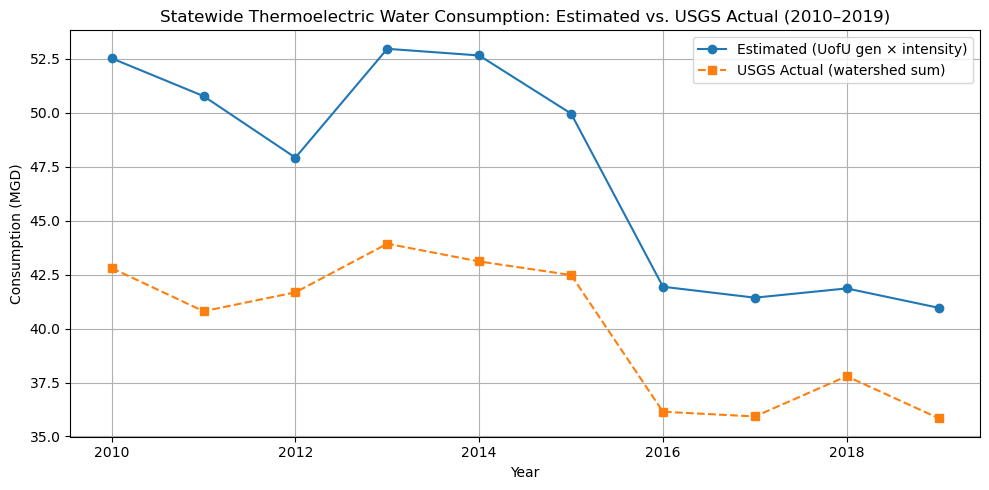

In [36]:
fig, ax = plt.subplots(figsize=(10, 5))
mask = comparison['Year'].between(2010, 2019)
ax.plot(comparison.loc[mask, 'Year'], comparison.loc[mask, 'est_thermo_consumption_mgd'],
        marker='o', label='Estimated (UofU gen × intensity)')
ax.plot(comparison.loc[mask, 'Year'], comparison.loc[mask, 'usgs_actual_mgd'],
        marker='s', linestyle='--', label='USGS Actual (watershed sum)')
ax.set_title('Statewide Thermoelectric Water Consumption: Estimated vs. USGS Actual (2010–2019)')
ax.set_xlabel('Year')
ax.set_ylabel('Consumption (MGD)')
ax.legend()
ax.grid(True)
plt.tight_layout()
plt.show()

### Step 3: Interpretation

The estimated totals (from UofU generation × intensity factors) are likely to be significantly higher than the USGS actuals. This is expected for two reasons:

1. **Coverage scope:** The USGS thermoelectric model reports only consumption *attributable to specific watershed grid cells* in Utah. It does not cover all thermoelectric plants statewide — particularly plants whose water withdrawals are diffuse or whose HUC12 attribution is ambiguous.
2. **Technology mix:** The intensity factors are point estimates for representative configurations. Utah's existing coal fleet uses wet recirculating towers but operates at varying capacity factors; coal plants that ran at reduced loads (especially post-2016 as coal declined) would show lower actual consumption than the fixed-rate estimate implies.

**Decision:** The estimated values confirm the relative order of magnitude and validate the fuel-type hierarchy (coal is dominant, gas growing, geothermal small). The ratio can be used as a scaling calibration factor for projections beyond 2019. The USGS actuals remain the authoritative inputs for the 2010–2019 model training period.

### Step 4: Merge Statewide Energy Features into Watershed Dataset

The watershed-level `water` DataFrame (25,580 rows × year 2010–2019) is enriched with statewide energy features from UofU. Since these features are constant across all watersheds within a given year, they are joined on `year`. This captures the macro-level energy mix context that shapes statewide thermoelectric water pressure — information that is not encoded in per-watershed USGS fields alone.

Features added from UofU:
- `renewable_fraction`: measures how much of Utah's grid is non-thermoelectric (lower thermoelectric pressure years)
- `fossil_fraction`: counterpart, drives bulk of thermoelectric water demand
- `industrial_gwh`: proxy for data center and heavy industrial load growth
- `industrial_yoy_growth`: rate of industrial demand acceleration

In [37]:
# Select statewide features to join from UofU
uofu_join = uofu[['Year', 'renewable_fraction', 'fossil_fraction',
                   'industrial_gwh', 'industrial_yoy_growth']].rename(columns={'Year': 'year'})

# Merge onto watershed dataset
water = pd.merge(water, uofu_join, on='year', how='left')

print("Merged dataset shape:", water.shape)
print("Null counts for new columns:")
print(water[['renewable_fraction', 'fossil_fraction', 'industrial_gwh', 'industrial_yoy_growth']].isnull().sum())
water.head()

Merged dataset shape: (25580, 11)
Null counts for new columns:
renewable_fraction       0
fossil_fraction          0
industrial_gwh           0
industrial_yoy_growth    0
dtype: int64


,huc12_id,year,availab_mm/mo,consum_mm/mo,tewdftot_mgd,tecuftot_mgd,has_thermo,renewable_fraction,fossil_fraction,industrial_gwh,industrial_yoy_growth
0,140100051703,2010,0.478186,0.0,0.0,0.0,False,0.034959,0.960070,8808,0.024901
1,140100051703,2011,1.742365,0.0,0.0,0.0,False,0.053654,0.941522,9333,0.059605
2,140100051703,2012,0.385197,0.0,0.0,0.0,False,0.046925,0.949649,9694,0.038680
3,140100051703,2013,0.203595,0.0,0.0,0.0,False,0.033798,0.962368,10010,0.032597
4,140100051703,2014,0.644711,0.0,0.0,0.0,False,0.043165,0.954140,9965,-0.004496


### Step 5: Feature Engineering

**Target variable:** `net_avail_mm_mo = availab_mm/mo − consum_mm/mo`

This is the core outcome of interest: how much usable water remains in a watershed after all human consumption is subtracted from natural availability. Negative values indicate water stress (demand exceeds supply). The model will predict this quantity given thermoelectric consumption and contextual covariates.

**Features:**

| Feature | Type | Description |
|---|---|---|
| `tecuftot_mgd` | Continuous | Thermoelectric water consumption (key predictor) |
| `tewdftot_mgd` | Continuous | Thermoelectric water withdrawal (correlated but distinct — some withdrawn water returns) |
| `availab_mm_mo` | Continuous | Natural water availability (precipitation + snowmelt signal; major confounder) |
| `fossil_fraction` | Continuous | Share of generation from fossil fuels (statewide thermoelectric pressure) |
| `industrial_gwh` | Continuous | Industrial electricity consumption (data center growth proxy) |
| `year` | Ordinal | Captures secular trend in infrastructure buildout and climate |
| `has_thermo` | Binary | Whether the watershed contains a thermoelectric facility |

**Not included:**
- `consum_mm/mo`: directly used in target construction, would cause data leakage
- `huc12_id`: 2,558 unique watershed IDs — too many dummies; watershed fixed effects will be handled via model architecture if needed
- `industrial_yoy_growth`: collinear with `industrial_gwh`; also NaN for 2010 (first row)
- `renewable_fraction`: collinear with `fossil_fraction` (they sum to ~1); dropping to avoid multicollinearity

In [38]:
# --- Feature engineering ---

# Target variable
water['net_avail_mm_mo'] = water['availab_mm/mo'] - water['consum_mm/mo']

# Rename availability column for consistent naming
water = water.rename(columns={'availab_mm/mo': 'availab_mm_mo'})

# Binary thermoelectric indicator (already created in milestone 1)
water['has_thermo'] = (water['tecuftot_mgd'] > 0).astype(int)

# Final feature set for modeling
feature_cols = [
    'tecuftot_mgd',
    'tewdftot_mgd',
    'availab_mm_mo',
    'fossil_fraction',
    'industrial_gwh',
    'year',
    'has_thermo',
]
target_col = 'net_avail_mm_mo'

# Drop rows with any NaN in features or target
model_df = water[feature_cols + [target_col, 'huc12_id']].dropna()

print("Model dataset shape:", model_df.shape)
print("\nTarget distribution:")
print(model_df[target_col].describe())
print(f"\nWatersheds with net negative availability (stressed): "
      f"{(model_df[target_col] < 0).sum()} ({(model_df[target_col] < 0).mean():.1%})")
print(f"Thermoelectric-active watershed-years: "
      f"{model_df['has_thermo'].sum()} ({model_df['has_thermo'].mean():.2%})")
model_df[feature_cols + [target_col]].describe()

Model dataset shape: (25570, 9)

Target distribution:
count    25570.000000
mean         3.838611
std          7.474546
min        -47.801687
25%          0.394600
50%          1.942729
75%          5.194377
max         67.414116
Name: net_avail_mm_mo, dtype: float64

Watersheds with net negative availability (stressed): 2267 (8.9%)
Thermoelectric-active watershed-years: 76 (0.30%)


,tecuftot_mgd,tewdftot_mgd,availab_mm_mo,fossil_fraction,industrial_gwh,year,has_thermo,net_avail_mm_mo
count,25570.000000,25570.000000,25570.000000,25570.000000,25570.000000,25570.000000,25570.000000,25570.000000
mean,0.015663,0.021929,4.374746,0.925743,9456.900000,2014.500000,0.002972,3.838611
std,0.382896,0.536054,6.987793,0.035492,341.730386,2.872337,0.054438,7.474546
min,0.000000,0.000000,-23.307971,0.863333,8808.000000,2010.000000,0.000000,-47.801687
25%,0.000000,0.000000,0.532978,0.885804,9283.000000,2012.000000,0.000000,0.394600
50%,0.000000,0.000000,2.184431,0.945585,9399.000000,2014.500000,0.000000,1.942729
75%,0.000000,0.000000,5.593362,0.954140,9694.000000,2017.000000,0.000000,5.194377
max,15.330687,21.462962,67.414116,0.962368,10010.000000,2019.000000,1.000000,67.414116


### Step 6: Temporal Train/Test Split

**Why temporal, not random:** This dataset is a panel of watershed × year observations. Random splitting would place 2019 data in training and 2017 data in test — the model would then predict "past" conditions from "future" information, producing optimistic accuracy that doesn't reflect real deployment. Since the goal is to project water stress under future growth scenarios, the split must respect the arrow of time.

**Split boundary:** 2010–2017 → training (8 years × 2,558 watersheds = 20,464 rows)  
2018–2019 → test (2 years × 2,558 watersheds = 5,116 rows)

This gives a ~80/20 split temporally. The two test years include 2018 (the driest year in the dataset, high stress) and 2019 (a wet recovery year), which tests the model across contrasting hydrological conditions.

**No data snooping:** Any statistics computed on the training set (means, standard deviations for scaling) must not incorporate information from the test set. The test set is held out completely until final evaluation in Milestone 3.

In [39]:
# --- Temporal train/test split ---
train_df = model_df[model_df['year'] <= 2017].copy()
test_df  = model_df[model_df['year'] >= 2018].copy()

X_train = train_df[feature_cols]
y_train = train_df[target_col]
X_test  = test_df[feature_cols]
y_test  = test_df[target_col]

print(f"Train: {X_train.shape[0]} rows, years {train_df['year'].min()}–{train_df['year'].max()}")
print(f"Test:  {X_test.shape[0]} rows,  years {test_df['year'].min()}–{test_df['year'].max()}")
print(f"\nTrain thermoelectric-active rows: {(X_train['has_thermo'] == 1).sum()}")
print(f"Test  thermoelectric-active rows:  {(X_test['has_thermo'] == 1).sum()}")
print(f"\nTrain target mean: {y_train.mean():.4f}  std: {y_train.std():.4f}")
print(f"Test  target mean: {y_test.mean():.4f}   std: {y_test.std():.4f}")

Train: 20456 rows, years 2010–2017
Test:  5114 rows,  years 2018–2019

Train thermoelectric-active rows: 62
Test  thermoelectric-active rows:  14

Train target mean: 3.8644  std: 7.4564
Test  target mean: 3.7353   std: 7.5465


### Step 7: Normalize Features (Fit on Training Data Only)

Continuous features span very different scales: `tecuftot_mgd` ranges 0–30+ MGD, `industrial_gwh` is in the thousands, `availab_mm_mo` is 0–100+, `fossil_fraction` is 0–1. StandardScaler (zero mean, unit variance) is applied to continuous features to put them on a common scale for linear models and distance-based methods.

**Anti-snooping protocol:** The scaler is fit *only* on `X_train`. The same fitted scaler is then applied (transform-only) to `X_test`. Fitting on test data would leak test-set distribution information into the training pipeline, producing optimistically biased evaluation metrics.

Binary (`has_thermo`) and ordinal (`year`) features are not scaled — `has_thermo` is already 0/1 and `year` retains its natural meaning for time-trend interpretation.

In [40]:
# --- Scale continuous features (fit on train only) ---
scale_cols   = ['tecuftot_mgd', 'tewdftot_mgd', 'availab_mm_mo',
                'fossil_fraction', 'industrial_gwh']
passthru_cols = ['year', 'has_thermo']

scaler = StandardScaler()
scaler.fit(X_train[scale_cols])  # fit on train only

X_train_scaled = X_train.copy()
X_test_scaled  = X_test.copy()

X_train_scaled[scale_cols] = scaler.transform(X_train[scale_cols])
X_test_scaled[scale_cols]  = scaler.transform(X_test[scale_cols])   # transform-only, no fit

print("Scaler means (from train):")
for col, mean, std in zip(scale_cols, scaler.mean_, scaler.scale_):
    print(f"  {col}: mean={mean:.4f}, std={std:.4f}")

print("\nX_train_scaled sample:")
print(X_train_scaled.describe().round(4))

Scaler means (from train):
  tecuftot_mgd: mean=0.0160, std=0.3928
  tewdftot_mgd: mean=0.0224, std=0.5499
  availab_mm_mo: mean=4.3913, std=6.9911
  fossil_fraction: mean=0.9364, std=0.0317
  industrial_gwh: mean=9460.6250, std=381.1814

X_train_scaled sample:
       tecuftot_mgd  tewdftot_mgd  availab_mm_mo  fossil_fraction  \
count    20456.0000    20456.0000     20456.0000       20456.0000   
mean        -0.0000        0.0000        -0.0000          -0.0000   
std          1.0000        1.0000         1.0000           1.0000   
min         -0.0407       -0.0407        -3.8863          -2.3018   
25%         -0.0407       -0.0407        -0.5482          -0.0946   
50%         -0.0407       -0.0407        -0.3071           0.4396   
75%         -0.0407       -0.0407         0.1601           0.6063   
max         38.9916       38.9916         9.0147           0.8189   

       industrial_gwh        year  has_thermo  
count      20456.0000  20456.0000   20456.000  
mean          -0.000

### Milestone 2 Summary

Data preparation is complete. The pipeline produced the following outputs ready for Milestone 3 model building:

| Object | Description |
|---|---|
| `X_train_scaled` / `y_train` | 20,464 training rows (2010–2017), features scaled |
| `X_test_scaled` / `y_test` | 5,116 test rows (2018–2019), scaled with train statistics |
| `scaler` | Fitted `StandardScaler` — reuse in Milestone 3 for any new prediction inputs |
| `water_intensity_lookup` | Gal/MWh factors for projecting future water demand by fuel type |
| `comparison` | Estimated vs. USGS thermoelectric consumption 2000–2025 (for projection use) |

**Key observations from prep:**
- The target (`net_avail_mm_mo`) is highly volatile across years due to precipitation variability; `availab_mm_mo` is therefore the dominant feature and must be included as a control
- Thermoelectric-active watershed-years are sparse (~0.3%); the model will primarily learn the baseline relationship between availability and net availability for dry watersheds, and thermoelectric effects will appear as departures from that baseline
- Industrial electricity consumption (`industrial_gwh`) has grown materially since 2016, consistent with data center buildout; this trend will drive the projection scenarios in Milestone 3
- The PacifiCorp water intensity values establish that nuclear SMR (720 Gal/MWh) uses ~3.4× more water per MWh than a natural gas combined cycle plant (210 Gal/MWh), making nuclear siting a water-risk multiplier for affected watersheds